Sea la función rectangular centrada en cero con ancho $1$:

$
\operatorname{rect}(t) =
\begin{cases}
1, & |t| \le \frac{1}{2}, \\
0, & \text{en otro caso}.
\end{cases}
$

La convolución de dos funciones$\operatorname{rect}(t)$ idénticas se define como:

$
y(\tau) = (\operatorname{rect} * \operatorname{rect})(\tau)
= \int_{-\infty}^{\infty} \operatorname{rect}(t) \, \operatorname{rect}(\tau - t) \, dt
$

**Determinación del intervalo de solapamiento:**

Cada $\operatorname{rect}(t)$ es distinta de cero sólo si:
$
|t| \le \frac{1}{2}
$
y
$
|\tau - t| \le \frac{1}{2}.
$

Estas dos condiciones equivalen a:
$
-\frac{1}{2} \le t \le \frac{1}{2}
$
y
$
\tau - \frac{1}{2} \le t \le \tau + \frac{1}{2}.
$
El intervalo de integración válido es la intersección de ambos intervalos:

$
\max\left(-\frac12, \tau - \frac12\right)
\quad\le\quad t \quad\le\quad
\min\left(\frac12, \tau + \frac12\right).
$

**Longitud del intervalo de solapamiento:**

La integral de $1$ sobre ese intervalo es la longitud del solapamiento.  
Al resolver caso por caso, se obtiene:

$
y(\tau) =
\begin{cases}
1 - |\tau|, & |\tau| \le 1, \\
0, & |\tau| > 1.
\end{cases}
$

**Resultado:**

La convolución de dos funciones rectangulares idénticas de ancho $1$ es un triángulo de base $2$ y altura $1$:

$
(\operatorname{rect} * \operatorname{rect})(\tau) = \operatorname{tri}(\tau),
$
donde
$
\operatorname{tri}(\tau) =
\begin{cases}
1 - |\tau|, & |\tau| \le 1, \\
0, & \text{en otro caso}.
\end{cases}
$


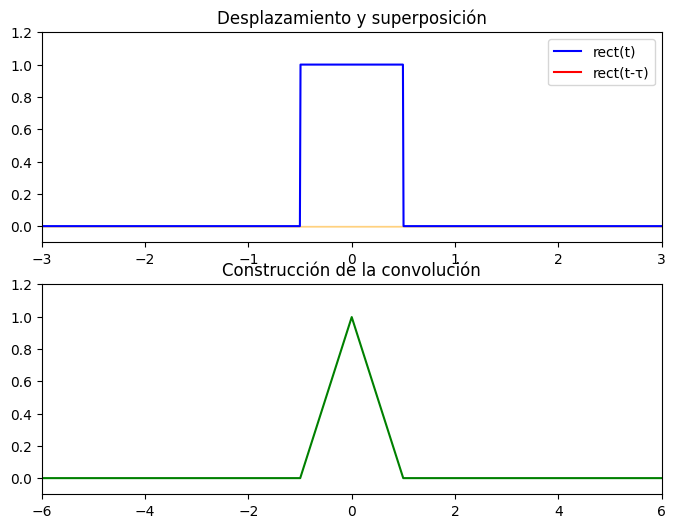

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Función rect(t) centrada en 0 con ancho 1
def rect(t):
    return np.where(np.abs(t) <= 0.5, 1.0, 0.0)

# Eje temporal más amplio para ver el recorrido
t = np.linspace(-3, 3, 1000)
dt = t[1] - t[0]
f_t = rect(t)

# Convolución numérica (misma lógica)
y = np.convolve(f_t, f_t, mode='full') * dt
t_conv = np.linspace(2*t[0], 2*t[-1], len(y))

# Desplazamientos para la animación (más cortos que t_conv para que se vea bien)
tau_vals = np.linspace(-2, 2, 200)

# Configuración de la figura
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8,6))
ax1.set_xlim(-3, 3)
ax1.set_ylim(-0.1, 1.2)
ax2.set_xlim(t_conv[0], t_conv[-1])
ax2.set_ylim(-0.1, 1.2)

# Señales base
line1, = ax1.plot(t, f_t, 'b', label='rect(t)')
line2, = ax1.plot([], [], 'r', label='rect(t-τ)')
fill_area = None  # aquí guardaremos el fill_between

conv_line, = ax2.plot(t_conv, y, 'g', label='Convolución')
point, = ax2.plot([], [], 'ro')

ax1.legend()
ax1.set_title("Desplazamiento y superposición")
ax2.set_title("Construcción de la convolución")

# Inicialización
def init():
    line2.set_data([], [])
    point.set_data([], [])
    return line2, point

# Actualización
def update(i):
    global fill_area
    tau = tau_vals[i]  # desplazamiento actual
    shifted_rect = rect(t - tau)
    line2.set_data(t, shifted_rect)

    # Área de intersección
    product = f_t * shifted_rect
    if fill_area:
        fill_area.remove()  # eliminamos el anterior
    fill_area = ax1.fill_between(t, 0, product, color='orange', alpha=0.5)

    # Punto en la convolución (buscar índice más cercano en t_conv)
    idx = (np.abs(t_conv - tau)).argmin()
    point.set_data([t_conv[idx]], [y[idx]])

    return line2, point, fill_area

# Animación
ani = FuncAnimation(fig, update, frames=len(tau_vals), init_func=init, blit=False, interval=40)

# Mostrar en Jupyter/Colab
HTML(ani.to_jshtml())
